In [153]:
# import des bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor


In [104]:
# Récupération du dataset
df = pd.read_csv('data/df_clean.csv')
df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
0,1,NonResidential,Hotel,Mayflower park hotel,405 Olive way,0659000030,7,DOWNTOWN,47.61220,-122.33799,...,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83
1,2,NonResidential,Hotel,Paramount Hotel,724 Pine street,0659000220,7,DOWNTOWN,47.61317,-122.33393,...,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86
2,3,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,0659000475,7,DOWNTOWN,47.61393,-122.33810,...,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19
3,5,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,0659000640,7,DOWNTOWN,47.61412,-122.33664,...,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67
4,8,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,0659000970,7,DOWNTOWN,47.61375,-122.34047,...,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88


# Exploration du dataset nettoyé

In [105]:
# information sur les données et les types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Data columns (total 37 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    1542 non-null   int64  
 1   BuildingType                     1542 non-null   str    
 2   PrimaryPropertyType              1542 non-null   str    
 3   PropertyName                     1542 non-null   str    
 4   Address                          1542 non-null   str    
 5   TaxParcelIdentificationNumber    1542 non-null   str    
 6   CouncilDistrictCode              1542 non-null   int64  
 7   Neighborhood                     1542 non-null   str    
 8   Latitude                         1542 non-null   float64
 9   Longitude                        1542 non-null   float64
 10  YearBuilt                        1542 non-null   int64  
 11  NumberofBuildings                1542 non-null   float64
 12  NumberofFloors                 

In [106]:
# Informations statistiques sur les colonnes numériques

df.describe()

,OSEBuildingID,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
count,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1526.000000,1.542000e+03,1542.000000,1.542000e+03,...,1542.000000,1.542000e+03,1.541000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1542.000000,1542.000000
mean,16470.426719,4.415045,47.616487,-122.333523,1961.588846,1.142023,4.262123,1.152784e+05,13872.791829,1.014056e+05,...,185.607588,8.024914e+06,8.156507e+06,4.982141e+05,1.652264e+06,5.637525e+06,1.852867e+04,1.852867e+06,176.163366,1.650415
std,13789.438674,2.192603,0.046978,0.023265,32.838734,1.182804,6.368218,1.978206e+05,43796.081781,1.753431e+05,...,188.065920,1.928942e+07,1.952623e+07,5.310227e+06,3.885019e+06,1.325569e+07,6.148985e+04,6.148985e+06,592.219483,2.265110
min,1.000000,1.000000,47.509590,-122.411820,1900.000000,1.000000,1.000000,1.128500e+04,0.000000,3.636000e+03,...,0.000000,5.713320e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.400000,0.010000
25%,602.250000,2.000000,47.587825,-122.343093,1930.000000,1.000000,1.000000,2.882525e+04,0.000000,2.791425e+04,...,84.674999,1.248602e+06,1.322417e+06,0.000000e+00,2.144374e+05,7.316600e+05,0.000000e+00,0.000000e+00,20.685000,0.360000
50%,21180.500000,4.000000,47.612615,-122.333170,1965.000000,1.000000,2.000000,4.806600e+04,0.000000,4.602500e+04,...,141.849998,2.727768e+06,2.824097e+06,0.000000e+00,5.109501e+05,1.743362e+06,4.910975e+03,4.910975e+05,49.940000,0.885000
75%,24603.750000,7.000000,47.649080,-122.322823,1988.000000,1.000000,4.000000,1.073940e+05,0.000000,9.530650e+04,...,215.674999,7.271161e+06,7.456910e+06,0.000000e+00,1.542024e+06,5.261384e+06,1.531061e+04,1.531061e+06,147.105000,1.960000
max,50226.000000,7.000000,47.733870,-122.261800,2015.000000,27.000000,76.000000,2.200000e+06,512608.000000,2.200000e+06,...,2620.000000,2.930908e+08,2.966717e+08,1.349435e+08,8.046087e+07,2.745325e+08,1.381912e+06,1.381912e+08,12307.160000,25.710000


In [107]:
# Informations sur les colonnes non numériques

df.describe(exclude=[np.number])

,BuildingType,PrimaryPropertyType,PropertyName,Address,TaxParcelIdentificationNumber,Neighborhood,ListOfAllPropertyUseTypes,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType
count,1542,1542,1542,1542,1542,1542,1542,1542,1542,1542
unique,5,20,1538,1521,1463,13,366,55,48,40
top,NonResidential,Small- and Mid-Sized Office,South Park,2600 SW Barton St,1625049001,DOWNTOWN,Office,Office,Aucun,Aucun
freq,1429,285,2,4,7,350,131,484,703,1197



ListOfAllPropertyUseTypes est comme son nom l'indique, une liste. 
Sachant que certaines informations de cette liste sont reprise dans les colonnes LargestPropertyUseType/SecondLargestPropertyUseType/ThirdLargestPropertyUseType, on peut modifier la liste en colonne numérique en la remplacant pas le nombre de types dans la liste 

In [108]:
# Remplacement de la liste par le nombre de types
df["ListOfAllPropertyUseTypes"] = df["ListOfAllPropertyUseTypes"].apply(lambda x : len(x.split(",")))

On retrouve des colonnes avec une forte cardinalité, c'est à dire avec quasiment autant de valeurs uniques que de lignes. 

Ce sont des colonnes identifiantes mais qui n'apportent pas d'intéret prédictive pour le modèle. 
En règle générale, il est préférable de supprimer les colonnes qui sont uniquement identifiantes et qui ne possèdent pas de réelle valeur prédictive.

In [109]:
# Suppression des colonnes à forte cardinalité
df = df.drop(columns = ["PropertyName","Address","TaxParcelIdentificationNumber"])

df.head()


,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,...,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,...,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,...,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,...,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,...,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88


les information qu'on ne pourra pas avoir sans relevés détaillés des propriétés 
On ne veut pas entraîner nos modèles dessus car on n'aura pas ces informations --> à drop:

 SiteEUI(kBtu/sf) -
  SiteEUIWN(kBtu/sf) -
 SourceEUI(kBtu/sf) -
 SourceEUIWN(kBtu/sf) -
 SiteEnergyUseWN(kBtu) -
 SteamUse(kBtu) -
 Electricity(kWh) -
 Electricity(kBtu) -
 NaturalGas(therms) -
 NaturalGas(kBtu) -              
 GHGEmissionsIntensity          



In [110]:
# Suppression des colonnes ayant de l'information énergétique : 
df = df.drop(columns=['SiteEUI(kBtu/sf)','SiteEUIWN(kBtu/sf)','SiteEnergyUseWN(kBtu)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'GHGEmissionsIntensity','SteamUse(kBtu)','Electricity(kWh)', 'Electricity(kBtu)','NaturalGas(therms)','NaturalGas(kBtu)'])

df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,...,ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,...,1,Hotel,88434.0,Aucun,0.0,Aucun,0.0,60.0,7226362.5,249.98
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,...,3,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,...,1,Hotel,756493.0,Aucun,0.0,Aucun,0.0,43.0,72587024.0,2089.28
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,...,1,Hotel,61320.0,Aucun,0.0,Aucun,0.0,56.0,6794584.0,286.43
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,...,3,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01


<Axes: >

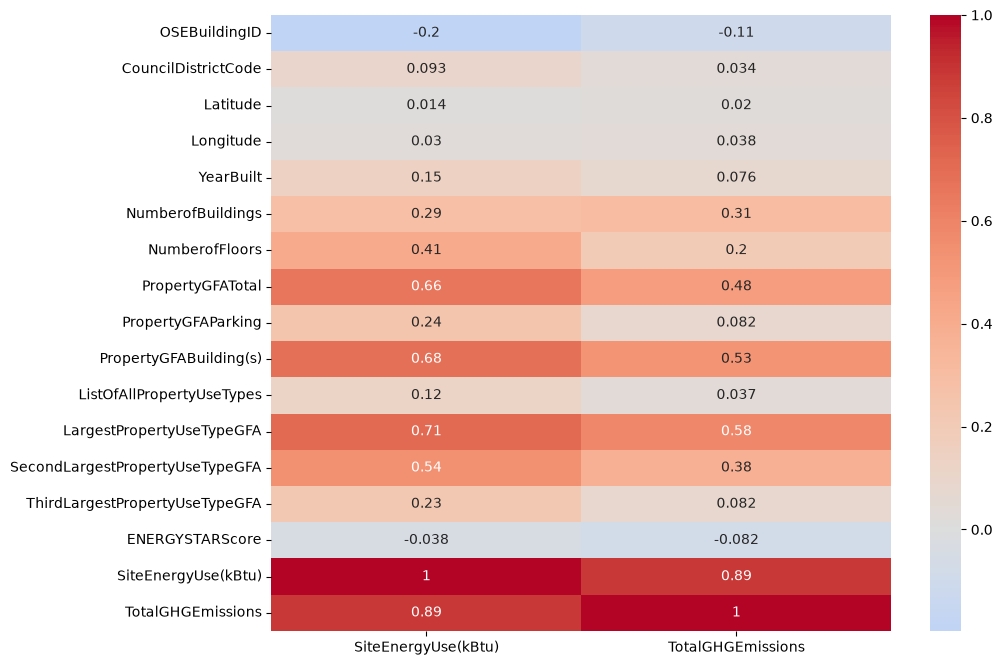

In [111]:
# détermination de la corrélation entre les colonnes numériques et les colonnes SiteEnergyUse(kBtu) et TotalGHGEmissions

corr_matrix = df.select_dtypes(include=['float64', 'int64']).corr()[['SiteEnergyUse(kBtu)','TotalGHGEmissions']]

# Visualisation de la corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

Colonnes avec une corrélation modérée à forte (>0.4) avec SiteEnergyUse(kBtu): 

    - (NumberOfBuildings)
    - (NumberOfFloors)
    - PropertyGFATotal
    - PropertyGFABuilding(s)
    - LargestPropertyUseTypeGFA
    - SecondLargestPropertyUseTypeGFA
    - (ThirdLargestPropertyUseTypeGFA)

(entre parenthèses --> éventuellement à supprimer pour voir si cela améliore le modèle)

TotalGHGEEmissions et SiteEnergyUse sont les cibles à prédire donc on ne les prends pas en compte.

Le ENERGYSTARScore n'a pas une corrélation importante mais le but est aussi de voir son importance alors on peu la garder pour l'instant

Le YearBuilt a une faible corrélation car il s'agit on recherche une consommation d'énergie et émissions totales, et non pas par rapport à la surface des bâtiments. Sachant que nous avons dans notre dataset également la surface, il peut être intéressant de garder cette colonne pour voir son influence

PropertyGFATotal concerne les bâtiments et les parkings, et PropertyGFABuilding(s) uniquement les bâtiments. Sachant que les parkings ne consomment pas beaucoup d'énergie et présentent une corrélation faible, et que PropertyGFABuilding(s) et PropertyGFATotal sont donc très proches, il serait judicieux de n'en garder qu'une des 2 pour éviter le phénomène de multicolinéarité

Malgré la transformation ListOfAllPropertyUseTypes, il ne semble pas y avoir de corrélation entre cette colonnes et nos cibles


In [112]:
columns_to_drop = [
    "OSEBuildingID",
    "CouncilDistrictCode",
    "Latitude",
    "Longitude",
    "PropertyGFATotal",
    "PropertyGFAParking",
    "ListOfAllPropertyUseTypes"
]

df = df.drop(columns=columns_to_drop)

df.head()

,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
0,NonResidential,Hotel,DOWNTOWN,1927,1.0,12.0,88434,Hotel,88434.0,Aucun,0.0,Aucun,0.0,60.0,7226362.5,249.98
1,NonResidential,Hotel,DOWNTOWN,1996,1.0,11.0,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86
2,NonResidential,Hotel,DOWNTOWN,1969,1.0,41.0,759392,Hotel,756493.0,Aucun,0.0,Aucun,0.0,43.0,72587024.0,2089.28
3,NonResidential,Hotel,DOWNTOWN,1926,1.0,10.0,61320,Hotel,61320.0,Aucun,0.0,Aucun,0.0,56.0,6794584.0,286.43
4,NonResidential,Hotel,DOWNTOWN,1980,1.0,18.0,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01


# Visualisations

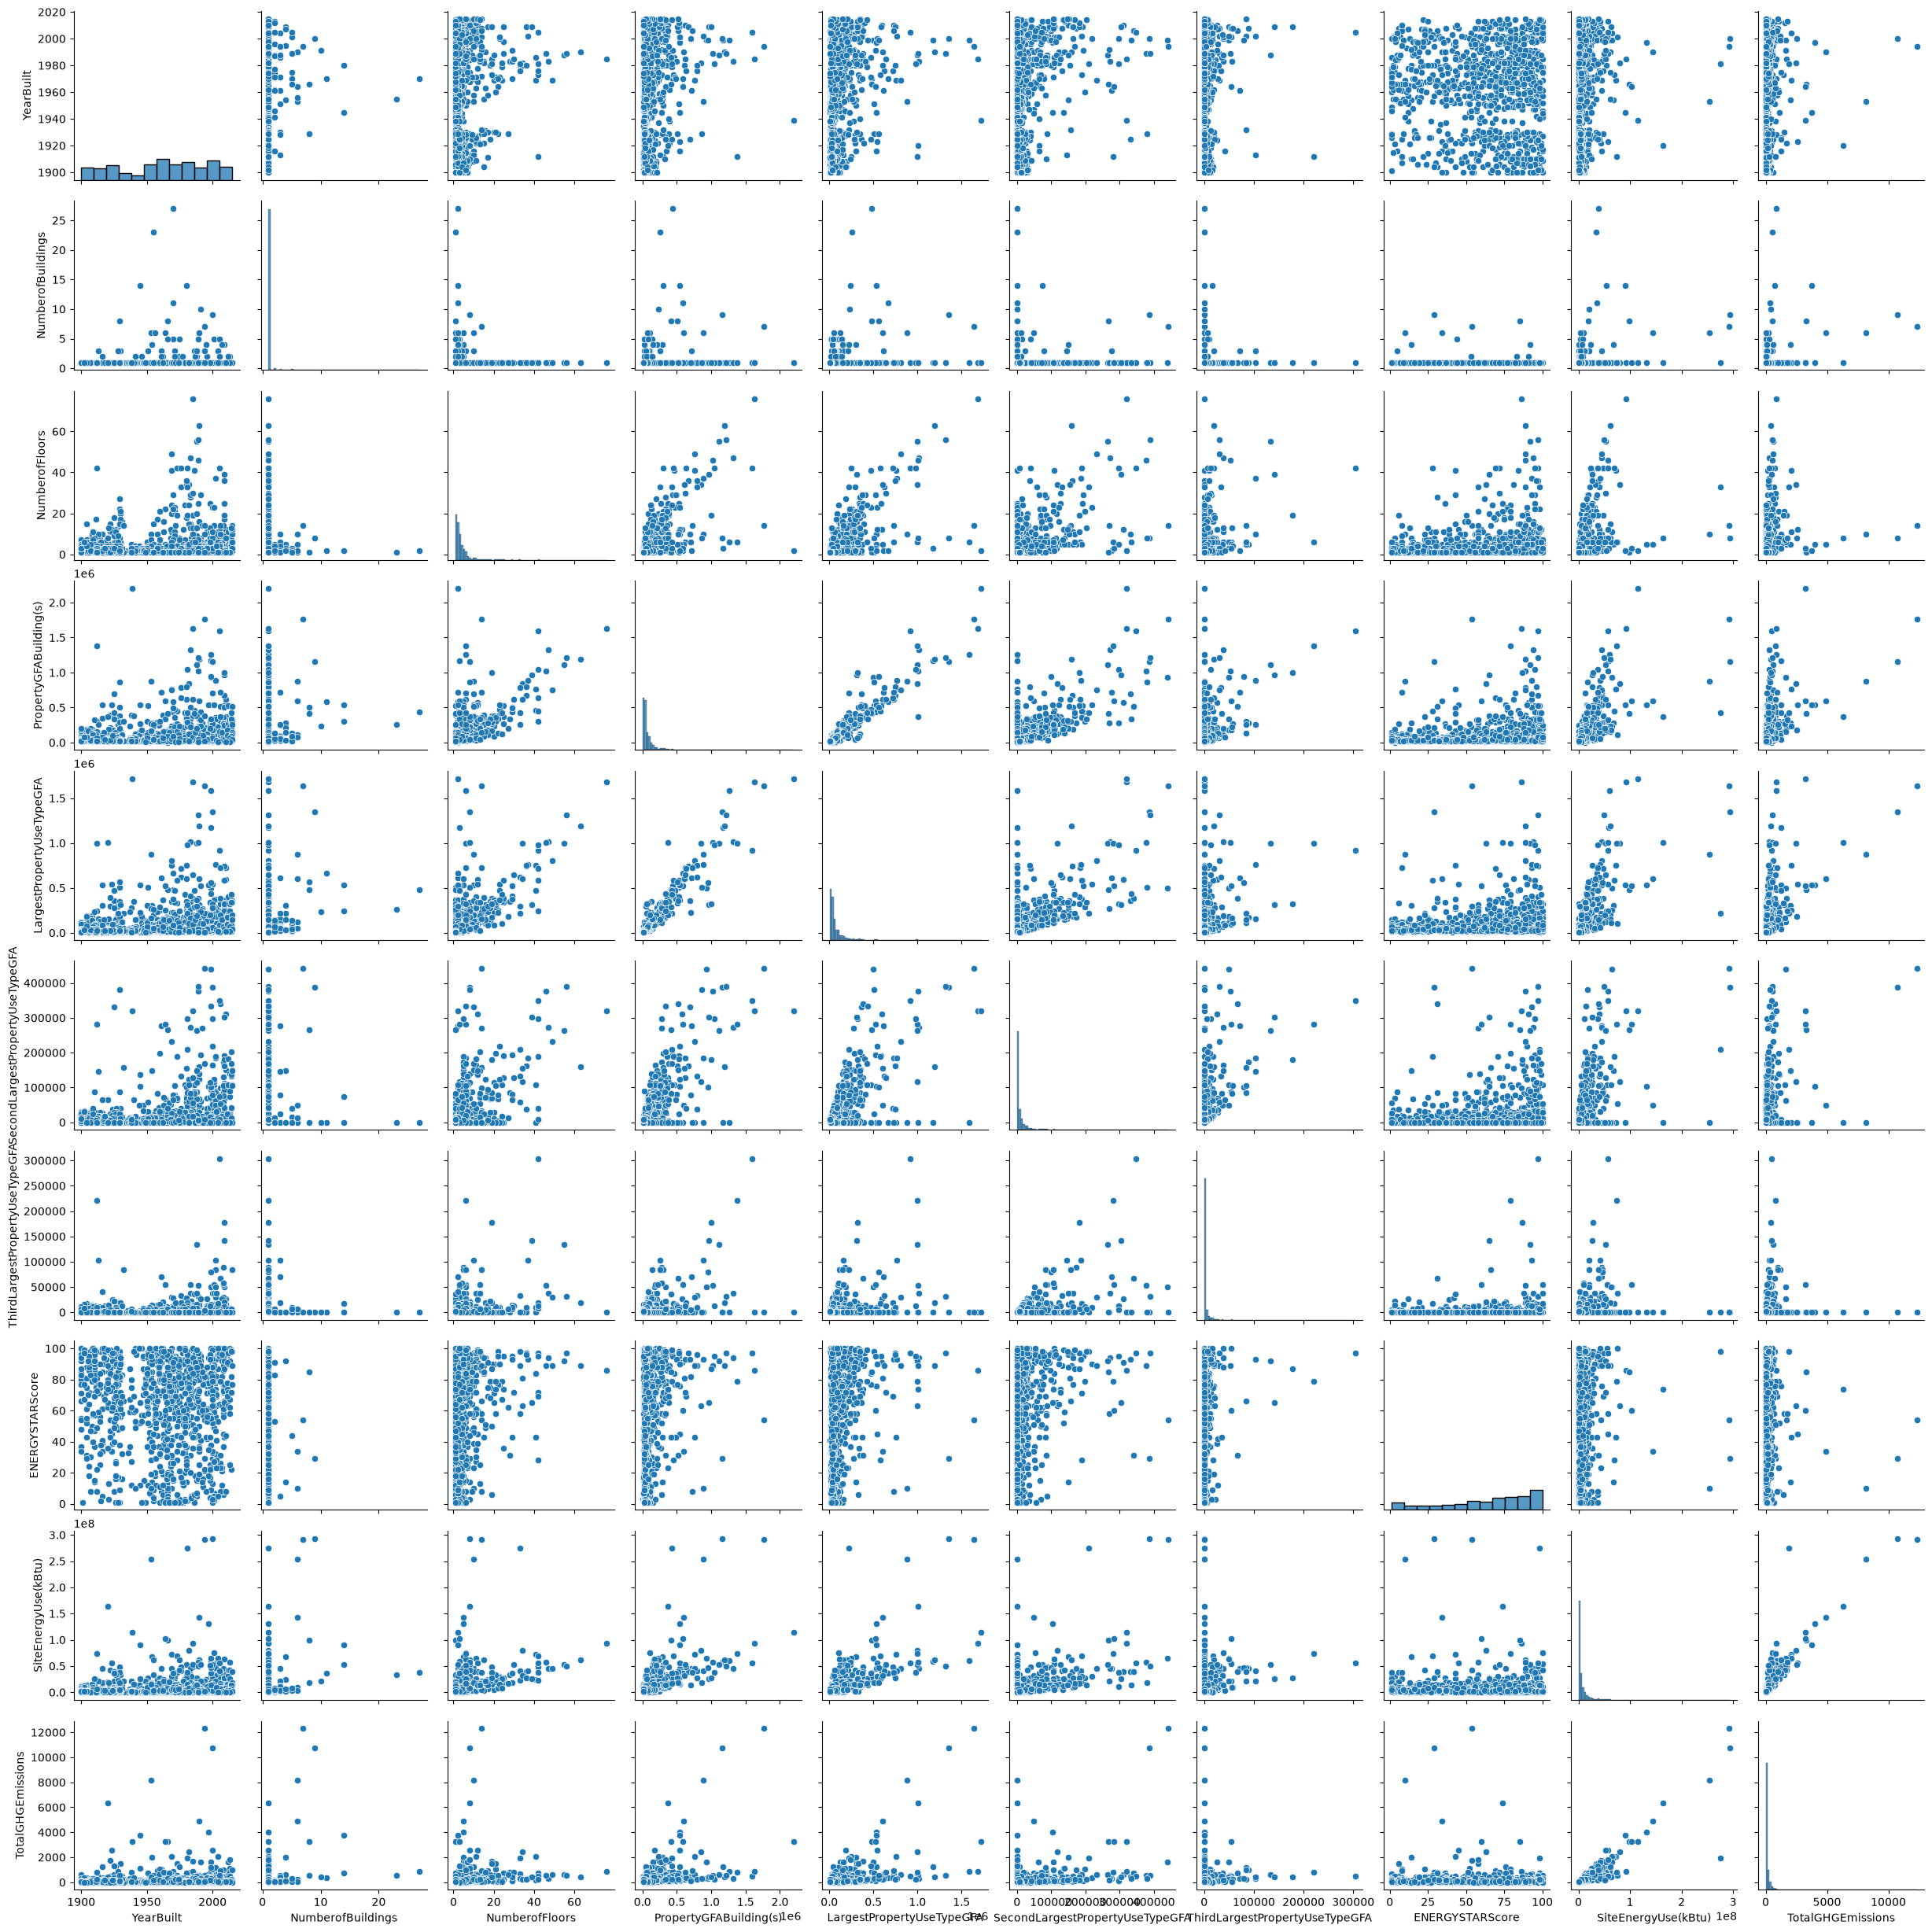

In [113]:
# Visualisations des relations des valeurs numérques dans notre df

sns.pairplot(df)

plt.show()

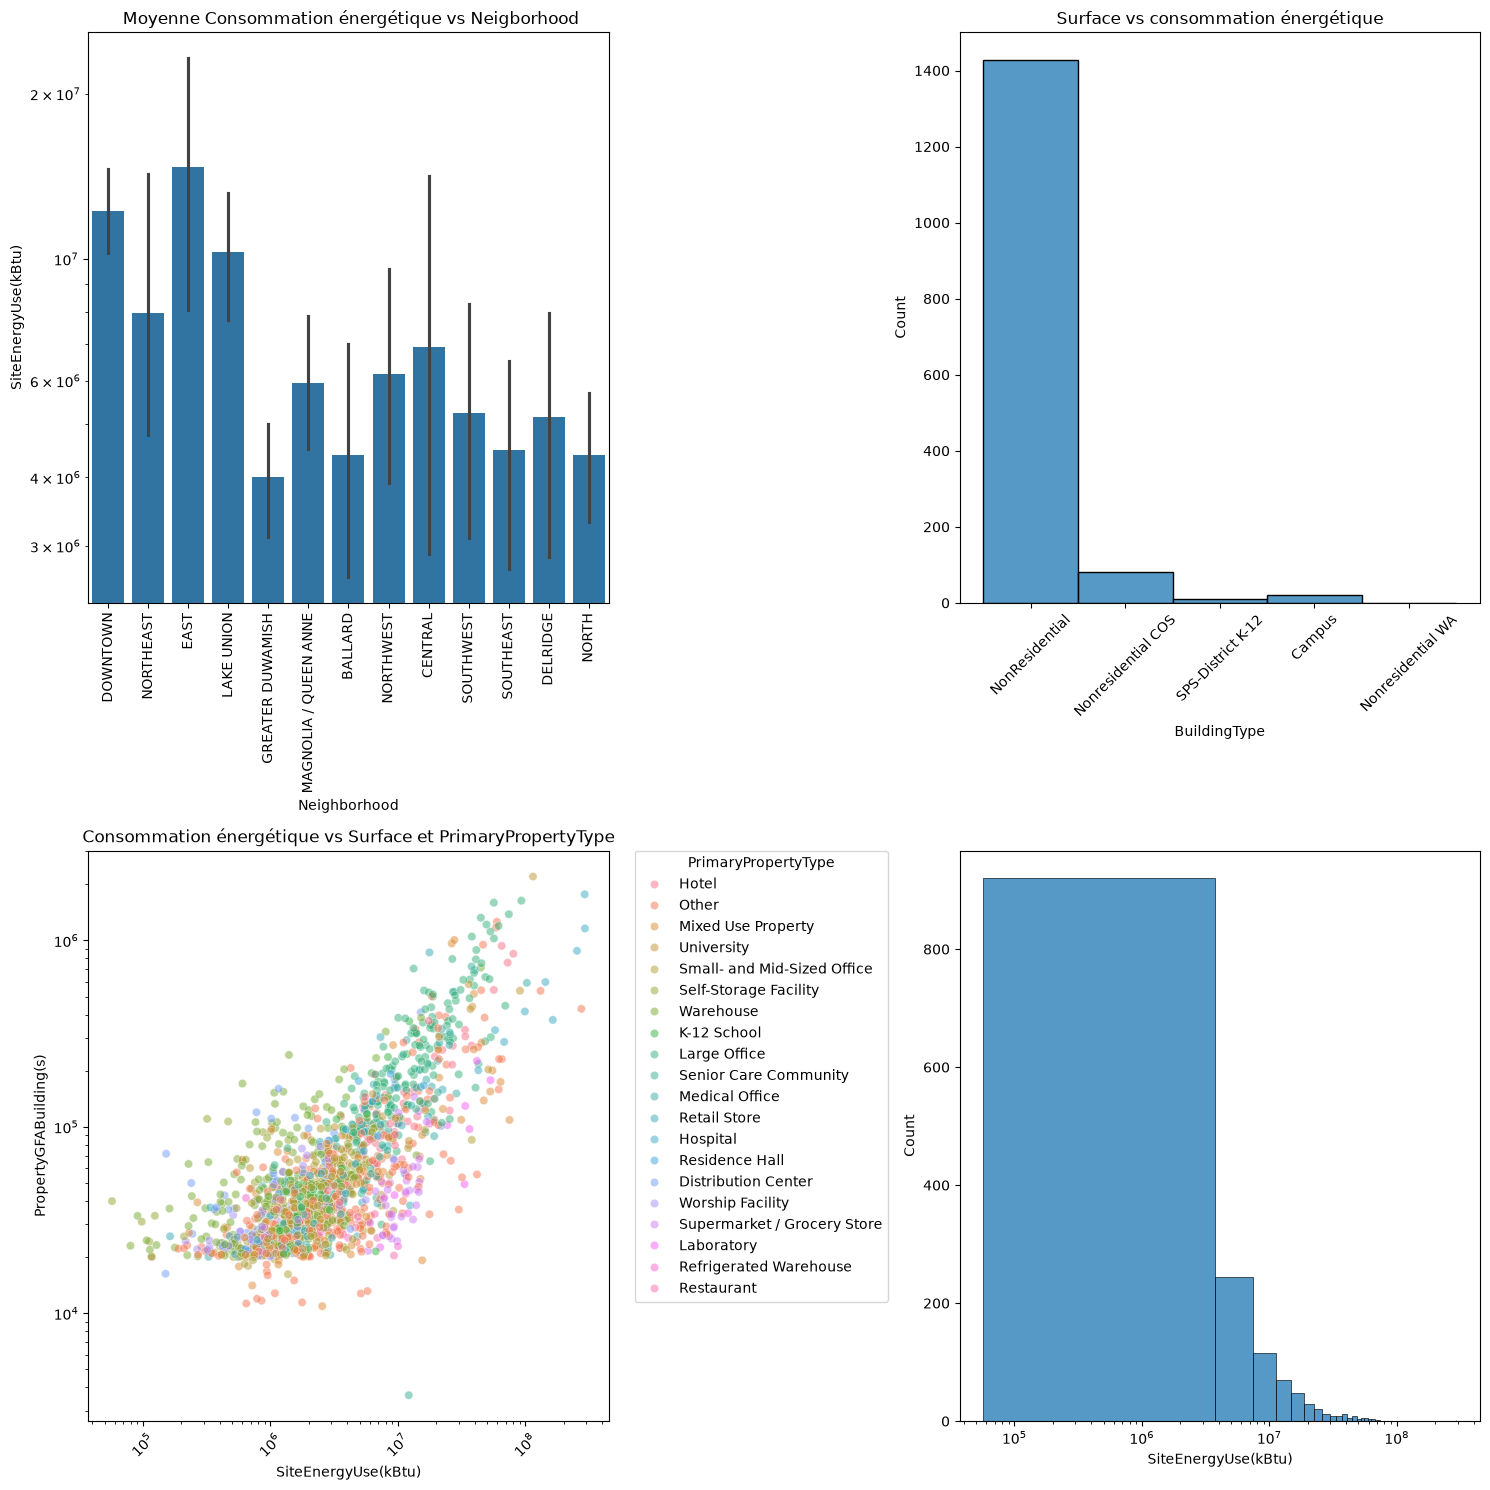

In [114]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

# Graphique 1 : Consommation énergétique selon la localisation géographique
sns.barplot(data = df, x = 'Neighborhood',y = 'SiteEnergyUse(kBtu)', ax = axes[0,0])
axes[0,0].set_yscale('log')
axes[0, 0].set_title(' Moyenne Consommation énergétique vs Neigborhood')

# Graphique 2 : Distribution des building types
sns.histplot(data=df,x='BuildingType',ax=axes[0, 1])
axes[0, 1].set_title('Building types')
axes[0, 1].set_title('Surface vs consommation énergétique')

# Graphique 3 : Energie, surface et Type de batiment
sns.scatterplot(data=df,x='SiteEnergyUse(kBtu)',y='PropertyGFABuilding(s)',hue = 'PrimaryPropertyType',ax=axes[1, 0],alpha=0.5)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Consommation énergétique vs Surface et PrimaryPropertyType')
axes[1, 0].legend(title='PrimaryPropertyType',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

# Graphique 4 : Energie, surface et Type de batiment
sns.histplot(data=df,x='SiteEnergyUse(kBtu)',ax=axes[1, 1])
axes[1, 1].set_xscale('log')

axes[0, 0].tick_params(axis='x', labelrotation=90)
axes[0, 1].tick_params(axis='x', labelrotation=45)
axes[1, 0].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

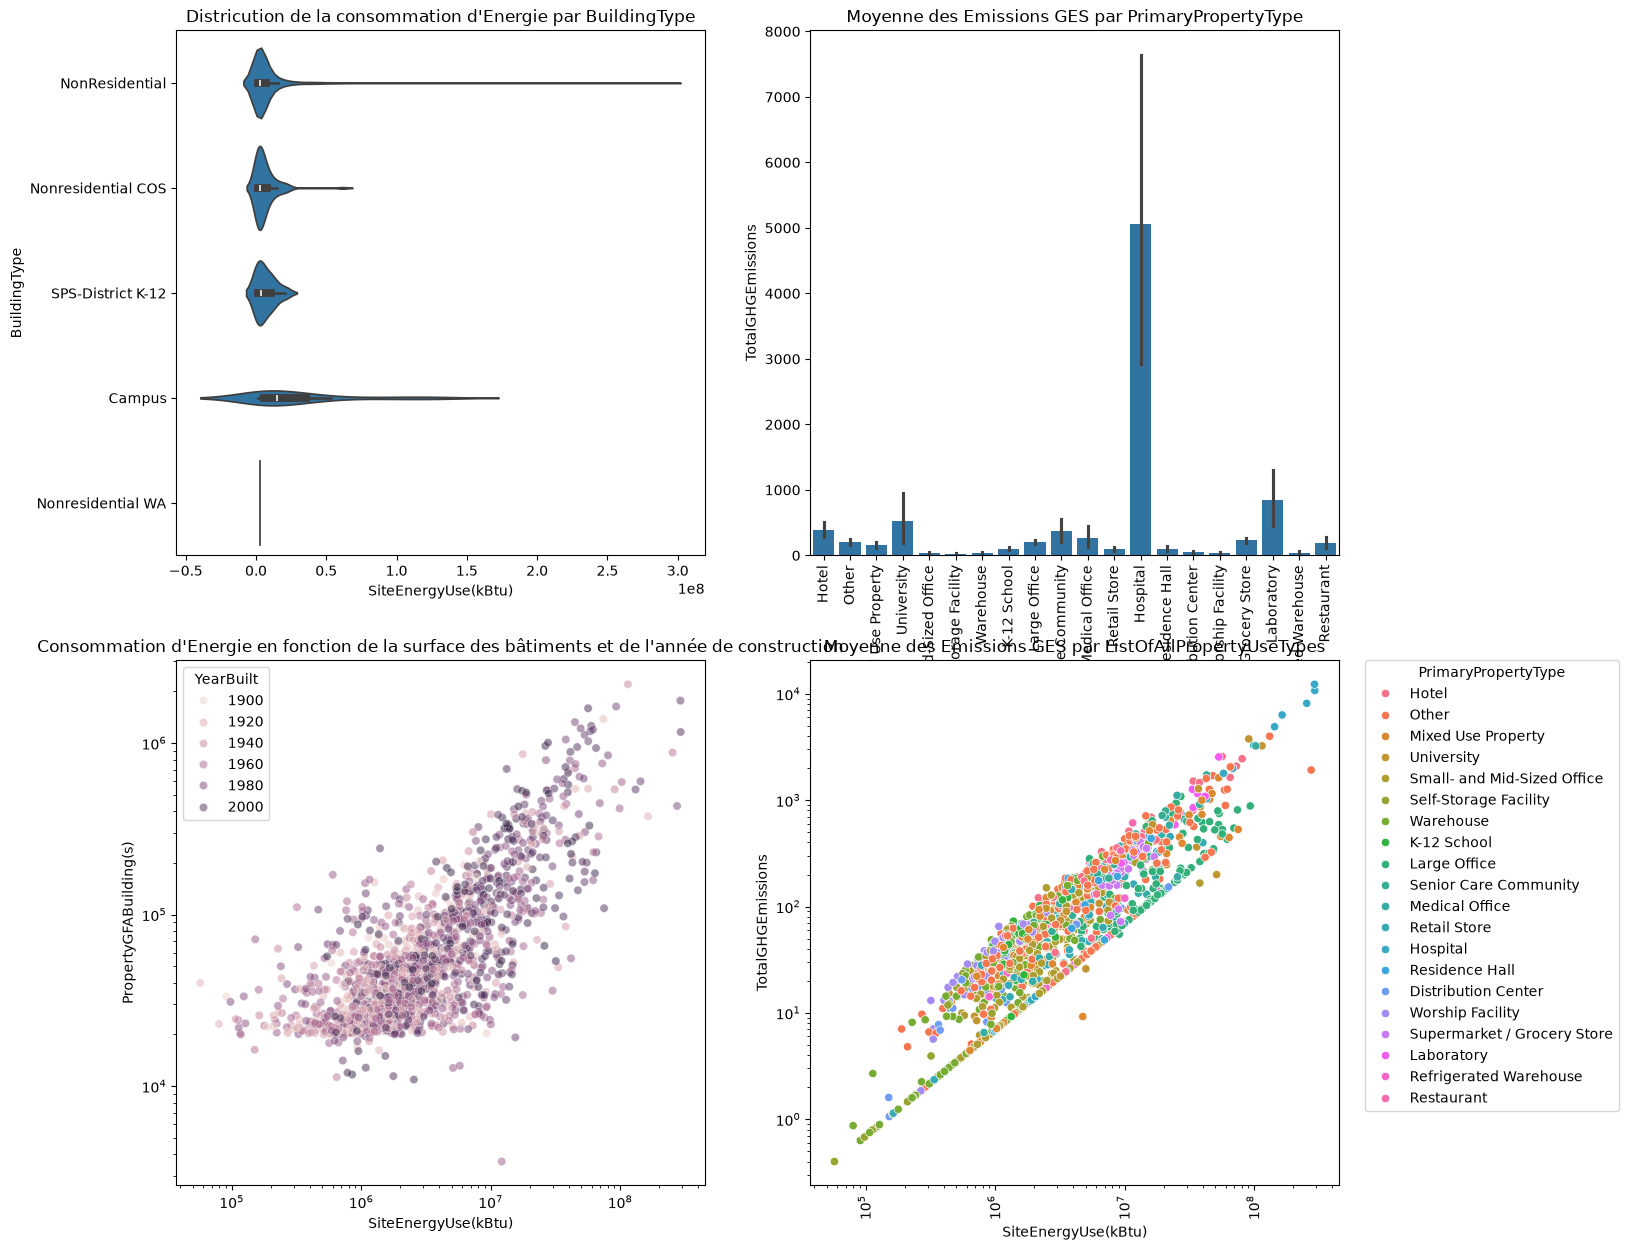

In [115]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

sns.violinplot(data=df, x = 'SiteEnergyUse(kBtu)' , y= 'BuildingType', ax=axes[0, 0] )
axes[0,0].set_title("Districution de la consommation d'Energie par BuildingType")

sns.barplot(data=df, x = 'PrimaryPropertyType' , y = 'TotalGHGEmissions', ax=axes[0, 1] )
axes[0, 1].tick_params(axis='x', labelrotation=90)
axes[0,1].set_title("Moyenne des Emissions GES par PrimaryPropertyType")

sns.scatterplot(data=df, x = 'SiteEnergyUse(kBtu)' , y = 'PropertyGFABuilding(s)', hue = 'YearBuilt', alpha = 0.5, ax=axes[1,0])
axes[1,0].set_title("Consommation d'Energie en fonction de la surface des bâtiments et de l'année de construction")
axes[1,0].set_xscale('log')
axes[1,0].set_yscale('log')

sns.scatterplot(data=df, x = 'SiteEnergyUse(kBtu)' , y = 'TotalGHGEmissions',hue = "PrimaryPropertyType", ax=axes[1, 1] )
axes[1,1].tick_params(axis='x', labelrotation=90)
axes[1,1].set_title("Moyenne des Emissions GES par ListOfAllPropertyUseTypes")
axes[1,1].set_yscale('log')
axes[1,1].set_xscale('log')
axes[1,1].legend(title='PrimaryPropertyType',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

In [116]:
# Visualisation des données où le nombre d'étages n'est pas renseigné

df[df['NumberofFloors'].isna() == True]

,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
129,NonResidential,Hotel,DOWNTOWN,1999,1.0,NaN,934292,Hotel,495536.0,Parking,438756.0,Restaurant,49700.0,NaN,6.504728e+07,1638.46
430,NonResidential,Medical Office,EAST,2004,1.0,NaN,225982,Medical Office,200184.0,Aucun,0.0,Aucun,0.0,53.0,2.056062e+07,692.12
431,NonResidential,Mixed Use Property,DOWNTOWN,2006,1.0,NaN,516407,Parking,385196.0,Multifamily Housing,340236.0,Hotel,67627.0,31.0,3.940332e+07,734.72
502,NonResidential,Other,DOWNTOWN,1999,1.0,NaN,947987,Other - Mall,561684.0,Other - Entertainment/Public Assembly,100000.0,Restaurant,80000.0,NaN,4.651096e+07,324.25
863,NonResidential,Worship Facility,GREATER DUWAMISH,1977,1.0,NaN,21948,Worship Facility,21948.0,Aucun,0.0,Aucun,0.0,80.0,3.260012e+05,2.27
990,NonResidential,Medical Office,EAST,1945,1.0,NaN,274568,Medical Office,228133.0,Parking,135954.0,Aucun,0.0,52.0,2.531153e+07,1110.07
1070,Campus,Other,GREATER DUWAMISH,1991,10.0,NaN,230971,Other,230970.0,Parking,0.0,Aucun,0.0,NaN,2.102229e+07,405.05
1454,NonResidential,Warehouse,NORTHEAST,1940,1.0,NaN,384772,Non-Refrigerated Warehouse,349953.0,Office,63872.0,Aucun,0.0,69.0,1.520676e+07,391.70
1455,NonResidential,Medical Office,NORTHEAST,1960,1.0,NaN,30287,Medical Office,28050.0,Aucun,0.0,Aucun,0.0,32.0,2.193115e+06,32.72
1456,NonResidential,Small- and Mid-Sized Office,NORTHEAST,1960,1.0,NaN,21931,Office,31845.0,Office,31845.0,Aucun,0.0,32.0,3.947209e+06,145.11


In [117]:
# Récupération des médians par PrimaryPropertyType
df.groupby("PrimaryPropertyType")["NumberofFloors"].median()

PrimaryPropertyType
Distribution Center            1.0
Hospital                       7.5
Hotel                          7.0
K-12 School                    2.0
Laboratory                     4.0
Large Office                   8.0
Medical Office                 3.0
Mixed Use Property             2.0
Other                          2.0
Refrigerated Warehouse         1.0
Residence Hall                 3.0
Restaurant                     2.5
Retail Store                   2.0
Self-Storage Facility          2.0
Senior Care Community          3.0
Small- and Mid-Sized Office    3.0
Supermarket / Grocery Store    1.0
University                     2.0
Warehouse                      1.0
Worship Facility               2.0
Name: NumberofFloors, dtype: float64

In [118]:
# Remplacement des données
df["NumberofFloors"] = df["NumberofFloors"].fillna(df.groupby("PrimaryPropertyType")["NumberofFloors"].transform("median"))

df['NumberofFloors'].isna().sum()

np.int64(0)

In [119]:
# Analyse des property GFA buildings vs la somme les différentes propriétés --> 574 lignes impactées 
sommesf = df["LargestPropertyUseTypeGFA"] + df["SecondLargestPropertyUseTypeGFA"] + df["ThirdLargestPropertyUseTypeGFA"]
totalsf = df["PropertyGFABuilding(s)"]
df[totalsf<sommesf]

# attention , j'ai pris uniquement la surface des bâtiments, alors que dans sommesf , il y a également la prise en compte des parkings

,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
1,NonResidential,Hotel,DOWNTOWN,1996,1.0,11.0,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.00,295.86
4,NonResidential,Hotel,DOWNTOWN,1980,1.0,18.0,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.00,505.01
5,Nonresidential COS,Other,DOWNTOWN,1999,1.0,2.0,60090,Police Station,88830.0,Aucun,0.0,Aucun,0.0,NaN,12086616.00,301.81
10,NonResidential,Hotel,DOWNTOWN,1998,1.0,25.0,272015,Hotel,336640.0,Aucun,0.0,Aucun,0.0,36.0,26941110.00,740.97
12,NonResidential,Hotel,DOWNTOWN,1980,1.0,33.0,258352,Hotel,295511.0,Parking,57600.0,Aucun,0.0,58.0,22325364.00,648.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1522,NonResidential,Hotel,LAKE UNION,2014,1.0,4.0,85284,Hotel,88157.0,Parking,41539.0,Swimming Pool,0.0,72.0,6042399.50,131.02
1523,NonResidential,Warehouse,GREATER DUWAMISH,1955,1.0,1.0,47863,Non-Refrigerated Warehouse,52085.0,Aucun,0.0,Aucun,0.0,37.0,3605855.50,157.70
1526,NonResidential,K-12 School,GREATER DUWAMISH,2015,1.0,3.0,45000,K-12 School,45728.0,Parking,0.0,Aucun,0.0,77.0,1325972.75,9.24
1527,NonResidential,Mixed Use Property,LAKE UNION,2015,1.0,6.0,260262,Laboratory,151523.0,Office,106498.0,Parking,84002.0,NaN,39364116.00,1000.06


In [120]:
# Il reste toujours des données manquantes dans la colonne ENERGYSTARScore, il faut les rempir avant de pouvoir l'injecter dans notre ML
df.groupby("PrimaryPropertyType")["ENERGYSTARScore"].median()

PrimaryPropertyType
Distribution Center            55.5
Hospital                       44.0
Hotel                          62.5
K-12 School                    79.0
Laboratory                      NaN
Large Office                   86.0
Medical Office                 51.0
Mixed Use Property             66.0
Other                          72.0
Refrigerated Warehouse         75.0
Residence Hall                 72.0
Restaurant                      NaN
Retail Store                   73.5
Self-Storage Facility           NaN
Senior Care Community          52.5
Small- and Mid-Sized Office    73.0
Supermarket / Grocery Store    40.5
University                      NaN
Warehouse                      60.0
Worship Facility               69.0
Name: ENERGYSTARScore, dtype: float64

In [121]:
# Remplacer les valeurs manquantes par le median par rapport au PrimaryPropertyType
df["ENERGYSTARScore"] = df["ENERGYSTARScore"].fillna(df.groupby("PrimaryPropertyType")["ENERGYSTARScore"].transform("median"))

# Remplacer les dernière valeurs numérique par le médian total
df["ENERGYSTARScore"] = df["ENERGYSTARScore"].fillna(df["ENERGYSTARScore"].median())

df['ENERGYSTARScore'].isna().sum()

np.int64(0)

In [122]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   BuildingType                     1542 non-null   str    
 1   PrimaryPropertyType              1542 non-null   str    
 2   Neighborhood                     1542 non-null   str    
 3   YearBuilt                        1542 non-null   int64  
 4   NumberofBuildings                1542 non-null   float64
 5   NumberofFloors                   1542 non-null   float64
 6   PropertyGFABuilding(s)           1542 non-null   int64  
 7   LargestPropertyUseType           1542 non-null   str    
 8   LargestPropertyUseTypeGFA        1542 non-null   float64
 9   SecondLargestPropertyUseType     1542 non-null   str    
 10  SecondLargestPropertyUseTypeGFA  1542 non-null   float64
 11  ThirdLargestPropertyUseType      1542 non-null   str    
 12  ThirdLargestPropertyUseTypeGFA 

In [154]:
# Enregistrement de df_clean
df.to_csv("data/df_features.csv", index = False)

# Encoder les colonnes de type string

## OneHotEncoder

On se retrouve avec 15 colonnes, il faut néansmoins encoder les colonnes qui ne sont pas des colonnes numériques : 
BuildingType - 
PrimaryPropertyType - 
Naigborhood -
LargestPropertyUseType -
SecondLargestPropertyUseType -
ThirdLargestPropertyUseType




In [123]:
df_encoded = df.copy()
df_encoded = pd.get_dummies(df,columns=["BuildingType","PrimaryPropertyType","Neighborhood","LargestPropertyUseType","SecondLargestPropertyUseType","ThirdLargestPropertyUseType"], drop_first=True, dtype=int)

df_encoded.head()

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions,...,ThirdLargestPropertyUseType_Refrigerated Warehouse,ThirdLargestPropertyUseType_Restaurant,ThirdLargestPropertyUseType_Retail Store,ThirdLargestPropertyUseType_Self-Storage Facility,ThirdLargestPropertyUseType_Social/Meeting Hall,ThirdLargestPropertyUseType_Strip Mall,ThirdLargestPropertyUseType_Supermarket/Grocery Store,ThirdLargestPropertyUseType_Swimming Pool,ThirdLargestPropertyUseType_Vocational School,ThirdLargestPropertyUseType_Worship Facility
0,1927,1.0,12.0,88434,88434.0,0.0,0.0,60.0,7226362.5,249.98,...,0,0,0,0,0,0,0,0,0,0
1,1996,1.0,11.0,88502,83880.0,15064.0,4622.0,61.0,8387933.0,295.86,...,0,1,0,0,0,0,0,0,0,0
2,1969,1.0,41.0,759392,756493.0,0.0,0.0,43.0,72587024.0,2089.28,...,0,0,0,0,0,0,0,0,0,0
3,1926,1.0,10.0,61320,61320.0,0.0,0.0,56.0,6794584.0,286.43,...,0,0,0,0,0,0,0,0,0,0
4,1980,1.0,18.0,113580,123445.0,68009.0,0.0,75.0,14172606.0,505.01,...,0,0,0,0,0,0,0,1,0,0


On obtient 185 colonnes ! 
Il faut faire une réduction de dimension avant de pouvoir entrainer notre modèle. Mais tout d'abord, pour éviter d'avoir des poids différents dépendant de la taille des valeurs numériques, il faut Standardiser les valeurs

On veut uniquement scale nos feature alors on les définit avant de standardiser

In [124]:
# Features
X = df_encoded.drop(columns = ["SiteEnergyUse(kBtu)","TotalGHGEmissions"])
# Cible Energie
y_energy = df_encoded["SiteEnergyUse(kBtu)"]
# Cible emissions CO2
y_co2 = df_encoded["TotalGHGEmissions"]

X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Columns: 183 entries, YearBuilt to ThirdLargestPropertyUseType_Worship Facility
dtypes: float64(6), int64(177)
memory usage: 2.2 MB


## Target Encoding

# Scaler

In [125]:
# Création du scaler afin de normaliser les données (résout le problème de poids des variables)
scaler = StandardScaler()

# Calcul des paramètres sur les données train
X_scaled = scaler.fit_transform(X)

X_scaled


array([[-1.05363584, -0.12011243,  1.22370322, ..., -0.08079242,
        -0.02547409, -0.02547409],
       [ 1.04822305, -0.12011243,  1.06587866, ..., -0.08079242,
        -0.02547409, -0.02547409],
       [ 0.22575653, -0.12011243,  5.80061526, ..., -0.08079242,
        -0.02547409, -0.02547409],
       ...,
       [ 0.37806515, -0.12011243, -0.51236687, ..., 12.37739876,
        -0.02547409, -0.02547409],
       [ 0.83499099, -0.12011243, -0.51236687, ..., -0.08079242,
        -0.02547409, -0.02547409],
       [-0.71855688, -0.12011243, -0.51236687, ..., -0.08079242,
        -0.02547409, -0.02547409]], shape=(1542, 183))

# Réduction de dimension

## Test ACP


In [126]:
# définition du reducteur de dimension (ACP)
pca = PCA()

# Application sur nos features
X_pca = pca.fit_transform(X_scaled)

X_pca

array([[ 5.97189779e-01,  7.48320901e-01, -1.62484527e+00, ...,
        -4.83706642e-16,  1.41168978e-16, -3.60865503e-16],
       [ 2.45360107e+00,  6.03164405e-01, -1.06594956e+00, ...,
         2.71465499e-15,  2.08827272e-16, -1.46363790e-16],
       [ 4.93159784e+00, -2.17377590e-01, -2.45430427e+00, ...,
        -5.80121781e-16, -2.04284154e-16, -1.14309158e-16],
       ...,
       [-1.77683899e+00, -1.06945079e+01,  2.01110811e+00, ...,
         2.84676469e-17,  1.13524108e-17, -3.24041673e-17],
       [-2.03075312e+00, -1.16486273e+01,  4.76958744e+00, ...,
         2.47680000e-17, -1.03190876e-17,  4.01899880e-17],
       [-2.14373791e+00, -1.15133652e+01,  4.85695459e+00, ...,
         1.13529670e-17,  6.20876888e-17,  2.59951302e-17]],
      shape=(1542, 183))

In [128]:
# Récuperer les axes qui expliquent 95% de variance cumulée 

variance_expliquee = pca.explained_variance_ratio_
variance_cumulee = np.cumsum(variance_expliquee)

for i, (var, cum) in enumerate(zip(variance_expliquee, variance_cumulee), 1):
    print(f"Axe PC{i} : {var:.2%} (Cumulé : {cum:.2%})")
    
# Méthode non adaptée, car au 26e axe --> que 33% de la variance


Axe PC1 : 2.80% (Cumulé : 2.80%)
Axe PC2 : 1.85% (Cumulé : 4.65%)
Axe PC3 : 1.64% (Cumulé : 6.30%)
Axe PC4 : 1.60% (Cumulé : 7.90%)
Axe PC5 : 1.36% (Cumulé : 9.26%)
Axe PC6 : 1.33% (Cumulé : 10.58%)
Axe PC7 : 1.30% (Cumulé : 11.89%)
Axe PC8 : 1.25% (Cumulé : 13.14%)
Axe PC9 : 1.23% (Cumulé : 14.37%)
Axe PC10 : 1.21% (Cumulé : 15.59%)
Axe PC11 : 1.21% (Cumulé : 16.80%)
Axe PC12 : 1.20% (Cumulé : 18.00%)
Axe PC13 : 1.19% (Cumulé : 19.19%)
Axe PC14 : 1.18% (Cumulé : 20.36%)
Axe PC15 : 1.16% (Cumulé : 21.53%)
Axe PC16 : 1.15% (Cumulé : 22.68%)
Axe PC17 : 1.14% (Cumulé : 23.82%)
Axe PC18 : 1.13% (Cumulé : 24.96%)
Axe PC19 : 1.13% (Cumulé : 26.09%)
Axe PC20 : 1.11% (Cumulé : 27.19%)
Axe PC21 : 1.09% (Cumulé : 28.28%)
Axe PC22 : 1.01% (Cumulé : 29.29%)
Axe PC23 : 0.97% (Cumulé : 30.26%)
Axe PC24 : 0.96% (Cumulé : 31.22%)
Axe PC25 : 0.88% (Cumulé : 32.10%)
Axe PC26 : 0.88% (Cumulé : 32.98%)
Axe PC27 : 0.85% (Cumulé : 33.83%)
Axe PC28 : 0.85% (Cumulé : 34.68%)
Axe PC29 : 0.83% (Cumulé : 35.51%)

Et si on ne garde que les colonnes de base numériques ? 

In [147]:
df_num = df.drop(columns=["BuildingType","PrimaryPropertyType","Neighborhood","LargestPropertyUseType","SecondLargestPropertyUseType","ThirdLargestPropertyUseType"])
df_num.info()

<class 'pandas.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   YearBuilt                        1542 non-null   int64  
 1   NumberofBuildings                1542 non-null   float64
 2   NumberofFloors                   1542 non-null   float64
 3   PropertyGFABuilding(s)           1542 non-null   int64  
 4   LargestPropertyUseTypeGFA        1542 non-null   float64
 5   SecondLargestPropertyUseTypeGFA  1542 non-null   float64
 6   ThirdLargestPropertyUseTypeGFA   1542 non-null   float64
 7   ENERGYSTARScore                  1542 non-null   float64
 8   SiteEnergyUse(kBtu)              1542 non-null   float64
 9   TotalGHGEmissions                1542 non-null   float64
dtypes: float64(8), int64(2)
memory usage: 120.6 KB


In [149]:
# Features
X_num = df_num.drop(columns = ["SiteEnergyUse(kBtu)","TotalGHGEmissions"])
# Cible Energie
y_energy_num = df_num["SiteEnergyUse(kBtu)"]
# Cible emissions CO2
y_co2_num = df_num["TotalGHGEmissions"]

In [151]:
# Création du scaler afin de normaliser les données (résout le problème de poids des variables)
scaler = StandardScaler()

# Calcul des paramètres sur les données train
X_scaled_num = scaler.fit_transform(X_num)

X_scaled_num

array([[-1.05363584e+00, -1.20112425e-01,  1.22370322e+00, ...,
        -3.88266301e-01, -2.11165661e-01, -2.50982303e-01],
       [ 1.04822305e+00, -1.20112425e-01,  1.06587866e+00, ...,
        -8.69829344e-02,  1.05630742e-01, -2.08378306e-01],
       [ 2.25756531e-01, -1.20112425e-01,  5.80061526e+00, ...,
        -3.88266301e-01, -2.11165661e-01, -9.75250257e-01],
       ...,
       [ 3.78065146e-01, -1.20112425e-01, -5.12366870e-01, ...,
        -2.76785056e-01, -2.11165661e-01,  2.60265664e-01],
       [ 8.34990992e-01, -1.20112425e-01, -5.12366870e-01, ...,
        -2.58244848e-01, -1.77991827e-01,  4.64168064e-03],
       [-7.18556884e-01, -1.20112425e-01, -5.12366870e-01, ...,
        -2.28264513e-01, -1.35222256e-01,  4.64168064e-03]],
      shape=(1542, 8))

In [152]:
# définition du reducteur de dimension (ACP)
pca = PCA()

# Application sur nos features
X_pca_num = pca.fit_transform(X_scaled_num)

# Récuperer les axes qui expliquent 95% de variance cumulée 

variance_expliquee = pca.explained_variance_ratio_
variance_cumulee = np.cumsum(variance_expliquee)

for i, (var, cum) in enumerate(zip(variance_expliquee, variance_cumulee), 1):
    print(f"Axe PC{i} : {var:.2%} (Cumulé : {cum:.2%})")

Axe PC1 : 43.75% (Cumulé : 43.75%)
Axe PC2 : 13.34% (Cumulé : 57.10%)
Axe PC3 : 12.68% (Cumulé : 69.77%)
Axe PC4 : 11.32% (Cumulé : 81.10%)
Axe PC5 : 9.59% (Cumulé : 90.69%)
Axe PC6 : 5.12% (Cumulé : 95.81%)
Axe PC7 : 3.79% (Cumulé : 99.60%)
Axe PC8 : 0.40% (Cumulé : 100.00%)


• n_components=4 (81,10 % de variance) : pour modèle très compact et éliminer un maximum de bruit.

• n_components=5 (90,69 % de variance) : plus sûr par défaut, il dépasse le seuil classique des 90 % tout en supprimant les 3 derniers axes peu utiles.

In [ ]:
# On refait mais cette fois-ci en pipeline


# 2. Découper en Train (80%) et Test (20%) AVANT toute transformation
X_train, X_test, y_train, y_test = train_test_split(X_num, y_energy_num, test_size=0.2, random_state=42)

# 3. Créer le Pipeline : Standardisation -> ACP (5 axes) -> Modèle de régression
# Exemple avec une régression linéaire régularisée (Ridge)
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=5)),
    ("modele", Ridge()) # Remplacez par RandomForestRegressor(random_state=42) pour tester du non-linéaire
])

# 4. Entraîner tout le pipeline sur le Train
pipeline.fit(X_train, y_train)

# 5. Évaluer sur le Test
y_pred = pipeline.predict(X_test)
print(f"R² sur le test : {r2_score(y_test, y_pred):.3f}")
print(f"Erreur moyenne (RMSE) : {root_mean_squared_error(y_test, y_pred):.3f}")

## PLS (Partial Least Squares) - Hybride - Réduction de dimension + Régression linéaire

In [ ]:
# 1. Séparation Train / Test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_energy, test_size=0.2, random_state=42)

# 2. Réduction à k composantes + prédiction directe
pls = PLSRegression(n_components=9)
pls.fit(X_train, y_train)

# Pour récupérer vos colonnes réduites (si vous voulez les passer à un autre modèle) :
X_train_pls = pls.transform(X_train)
X_test_pls = pls.transform(X_test)

# Pour évaluer directement la performance de prédiction :
y_pred = pls.predict(X_test)
print(f"R² : {r2_score(y_test, y_pred):.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.3f}")

R² : 0.761
RMSE : 9881625.145


# Modèles de régression

## Régression linéaire

La régression linéaire est une méthode statistique qui utilise des données de valeur connue pour prédire la valeur de données inconnues. La relation entre une ou plusieurs variables dépendantes et indépendantes est modélisée en ajustant une équation linéaire aux données observées. Les méthodes de régression linéaire excellent dans la détection de modèles dans les données historiques, offrant aux équipes marketing et commerciales une compréhension détaillée de la façon dont le comportement des clients, l'utilisation des services, la tarification et les données démographiques ont un impact sur les taux d'attrition. La régression linéaire multiple peut aider les entreprises à prédire l'attrition des clients en identifiant et en quantifiant les principaux facteurs incitant un client à partir.

## Régression polynomiale

La régression polynomiale est une forme avancée de régression linéaire utilisée pour capturer des modèles complexes dans les données. Elle modélise la relation entre les variables dépendantes et indépendantes sous la forme d'un polynôme de degré n. En ajustant une équation non linéaire aux données, elle peut capturer des relations non linéaires, ce qui la rend utile lors de l'utilisation d'ensembles de données complexes. Ce type de modèle de régression est couramment utilisé dans les applications de services financiers. Avec la capacité de capturer des interactions non linéaires entre des variables telles que l'âge, l'historique de conduite et le type de véhicule, la régression polynomiale permet aux assureurs de mieux évaluer les facteurs de risque et de prédire les résultats, ce qui se traduit par des décisions de souscription plus éclairées.

## Régression Ridge

La régression Ridge est une méthode de régularisation statistique utilisée pour corriger le surapprentissage sur les données d'entraînement des modèles de machine learning. La régression Ridge est un bon choix pour analyser la multicolinéarité, la présence de fortes intercorrélations entre deux ou plusieurs variables indépendantes au sein d'un modèle de régression multiple. Cela empêche le surapprentissage en ajoutant une pénalité aux coefficients de régression. Dans le domaine de la santé, la régression Ridge est utilisée pour identifier la relation entre un grand nombre de facteurs génétiques, liés au mode de vie et environnementaux, et le risque de développer des maladies spécifiques. Ce type de régression peut jouer un rôle important dans la création de modèles plus puissants et plus fiables pour prédire le risque de maladie individuelle en fonction de nombreux facteurs complexes et interdépendants.

## Régression Lasso

La régression Lasso (Least Absolute Shrinkage and Selection Operator) est une forme de régression linéaire qui utilise la contraction, les coefficients étant réduits vers un point central, comme la moyenne. Un cas d'usage principal de la régression Lasso est l'automatisation de la sélection de features. La régression Lasso sélectionne automatiquement les features utiles, éliminant les features inutiles ou redondantes.

## Régression elastic net

La régression elastic net fusionne les pénalités des régressions Lasso et Ridge, ce qui donne un modèle de régression en machine learning capable de trouver un équilibre entre la sélection de variables et la gestion de la multicolinéarité dans les modèles prédictifs. Dans le contexte de l'analyse sportive, la capacité de la régression elastic net à gérer un large éventail de variables corrélées (telles que les statistiques des joueurs, les mesures physiques et les conditions de jeu) la rend utile pour analyser la performance des joueurs et prédire les résultats des matchs.